# 03 — Apprendre par batchs : séquences `(B, T)` et *reshape*

**Chapitre 2** · durée conseillée : 25 min · CPU uniquement · [![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/chapitre_2/03_batch_learning.ipynb)

![Parcours](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/00_parcours.png)

Au notebook 02, chaque exemple était une **paire isolée** (caractère → suivant). Pour qu'un modèle utilise le **contexte**, il faut lui donner des **morceaux de texte**. Ce notebook installe les bases des données qui servira jusqu'au GPT.

**À la fin de ce notebook, vous saurez :**
1. pourquoi on apprend sur des **mini-batchs** et non sur tout le corpus ;
2. ce que sont `block_size` (**T**) et `batch_size` (**B**), et pourquoi une fenêtre de `T` caractères contient `T` exemples ;
3. écrire `get_batch` ;
4. expliquer le passage `(B, T, V) → (B·T, V)` avant `F.cross_entropy`, et pourquoi il ne change aucune valeur.

**Notations du chapitre :** **B** = taille du batch, **T** = longueur de contexte (*block_size*), **V** = taille du vocabulaire, **C** = nombre de caractéristiques par token (*n_embd*).

In [ ]:
# Sur Google Colab : récupérer le dépôt du cours (corpus + modules partagés comme minigpt.py).
# En local, cette cellule ne fait rien.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/chapitre_2

In [ ]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

CORPUS = "shakespeare" # "kaamelott" / "platon"
texte, tok, train_data, val_data = minigpt.preparer_donnees(CORPUS)
V = tok.vocab_size

PyTorch 2.14.1+cu130 | périphérique : cpu


## 1. Pourquoi des mini-batchs ?

On pourrait calculer la loss sur **tout** le corpus à chaque pas (c'est ce que faisait le chapitre 1 avec les prénoms). Trois raisons de ne pas le faire :

1. **Mémoire.** Pour le GPT, chaque caractère produit des activations de taille `C` dans chaque couche. Sur 1 M de caractères, cela ne tient pas en mémoire.
2. **Vitesse.** Un gradient estimé sur quelques milliers de caractères est **presque aussi bon** qu'un gradient exact, et coûte des centaines de fois moins cher. Mieux vaut faire beaucoup de petits pas approximatifs que peu de grands pas exacts.
3. **Parallélisme.** Les processeurs (et surtout les GPU) calculent efficacement **plusieurs exemples d'un coup** sous forme de tenseurs.

Le prix à payer : la loss d'un batch est une **estimation bruitée**. Mesurons ce bruit avec un bigramme déjà entraîné.

loss sur TOUT le corpus d'entraînement : 2.494


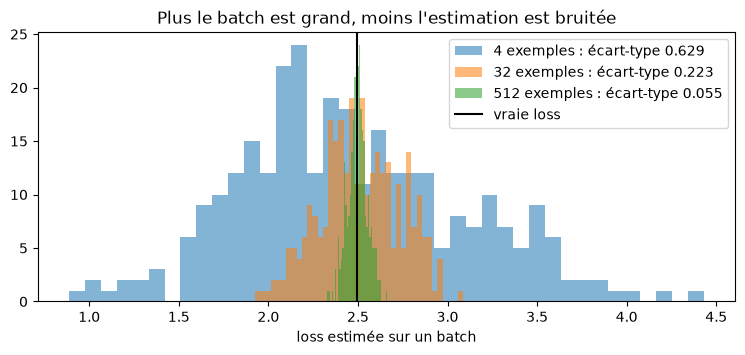

In [2]:
# Un bigramme entraîné rapidement (même code qu'au notebook 02, version minigpt)
torch.manual_seed(1337)
table = nn.Embedding(V, V)
opt = torch.optim.AdamW(table.parameters(), lr=0.1)
for _ in range(300):
    ix = torch.randint(len(train_data) - 1, (256,))
    loss = F.cross_entropy(table(train_data[ix]), train_data[ix + 1])
    opt.zero_grad(); loss.backward(); opt.step()

with torch.no_grad():
    vraie = F.cross_entropy(table(train_data[:-1]), train_data[1:]).item()
    print(f"loss sur TOUT le corpus d'entraînement : {vraie:.3f}")
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for n in [4, 32, 512]:
        estim = []
        for _ in range(300):
            ix = torch.randint(len(train_data) - 1, (n,))
            estim.append(F.cross_entropy(table(train_data[ix]), train_data[ix + 1]).item())
        estim = torch.tensor(estim)
        ax.hist(estim, bins=40, alpha=.55, label=f"{n} exemples : écart-type {estim.std():.3f}")
    ax.axvline(vraie, color="black", label="vraie loss")
    ax.set_xlabel("loss estimée sur un batch"); ax.legend(); ax.set_title("Plus le batch est grand, moins l'estimation est bruitée")
    plt.show()

L'écart-type diminue environ comme $1/\sqrt{\text{taille du batch}}$ : multiplier le batch par 16 divise le bruit par 4. En pratique, on choisit le plus grand batch qui tient en mémoire et reste rapide.

---
## 2. Des paires aux fenêtres de contexte

Au lieu de paires, on découpe le texte en **fenêtres** de `block_size = T` caractères. L'entrée `x` et la cible `y` sont **décalées d'un cran** :

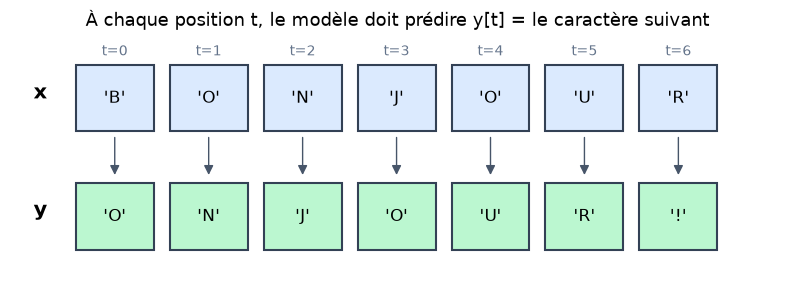

In [3]:
# Une séquence fournit plusieurs exemples de prédiction.
# Modifiez la phrase et observez comment x et y se décalent.
from matplotlib.patches import Rectangle, FancyArrowPatch

phrase = "BONJOUR!"                    # 8 caractères : 7 exemples
x_vis, y_vis = phrase[:-1], phrase[1:]
T_vis = len(x_vis)
fig, ax = plt.subplots(figsize=(max(10, T_vis * 1.25), 3.4))
ax.set_xlim(-0.7, T_vis + 0.55); ax.set_ylim(-0.4, 2.7); ax.axis("off")
for t in range(T_vis):
    for y0, char, bg in [(1.55, x_vis[t], "#dbeafe"), (0.15, y_vis[t], "#bbf7d0")]:
        ax.add_patch(Rectangle((t, y0), .83, .79, facecolor=bg, edgecolor="#334155", lw=1.5))
        ax.text(t + .415, y0 + .39, repr(char), ha="center", va="center", fontsize=12)
    ax.text(t + .415, 2.45, f"t={t}", ha="center", fontsize=10, color="#64748b")
    ax.add_patch(FancyArrowPatch((t + .415, 1.51), (t + .415, 1.0), arrowstyle="-|>", mutation_scale=14, color="#475569"))
ax.text(-.3, 1.94, "x", fontsize=15, fontweight="bold", ha="right")
ax.text(-.3, .55, "y", fontsize=15, fontweight="bold", ha="right")
ax.set_title("À chaque position t, le modèle doit prédire y[t] = le caractère suivant", fontsize=13)
plt.show()

**Une fenêtre de `T` caractères contient `T` exercices**, de difficulté croissante :

In [4]:
block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]
for t in range(block_size):
    contexte, cible = x[:t + 1], y[t]
    print(f"contexte {tok.decode(contexte)!r:14s} -> cible {tok.itos[cible.item()]!r}")

contexte 'F'            -> cible 'i'
contexte 'Fi'           -> cible 'r'
contexte 'Fir'          -> cible 's'
contexte 'Firs'         -> cible 't'
contexte 'First'        -> cible ' '
contexte 'First '       -> cible 'C'
contexte 'First C'      -> cible 'i'
contexte 'First Ci'     -> cible 't'


Deux remarques importantes pour la suite :

- **Le contexte varie de 1 à T caractères.** Le modèle apprend donc aussi à prédire avec peu de contexte, ce qui est indispensable pour démarrer une génération à partir d'un seul caractère.
- **La position `t` ne doit voir que `x[:t+1]`.** Si elle pouvait lire `x[t+1]`, elle lirait… la réponse `y[t]`. Le **masque causal** du notebook 05 garantira cette règle.

---
## 3. `get_batch` : B fenêtres tirées au hasard

![Un batch](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/03_batch.png)

On tire `B` positions de départ au hasard et on **empile** les fenêtres avec `torch.stack`. Le résultat est un tenseur `(B, T)` d'indices. Chaque ligne est un extrait indépendant : **les lignes d'un batch ne communiquent jamais entre elles**.

In [5]:
def get_batch(data, batch_size, block_size, device="cpu"):
    """Tire batch_size fenêtres de block_size caractères ; y = x décalé d'un cran."""
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i + block_size] for i in ix])
    y = torch.stack([data[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)


torch.manual_seed(1337)
xb, yb = get_batch(train_data, batch_size=4, block_size=8)
print("xb :", tuple(xb.shape), "| yb :", tuple(yb.shape))
for b in range(4):
    print(f"b={b}  x = {tok.decode(xb[b])!r:14s}  y = {tok.decode(yb[b])!r}")
print(f"\n4 × 8 = {xb.numel()} prédictions à faire dans ce batch")

xb : (4, 8) | yb : (4, 8)
b=0  x = "Let's he"      y = "et's hea"
b=1  x = 'for that'      y = 'or that '
b=2  x = 'nt that '      y = 't that h'
b=3  x = 'MEO:\nI p'     y = 'EO:\nI pa'

4 × 8 = 32 prédictions à faire dans ce batch


**Question :** pourquoi `torch.randint(len(data) - block_size, ...)` et pas `len(data)` ? *(Indice : que vaudrait `y` si la fenêtre commençait sur le dernier caractère ?)*

---
## 4. Le problème : `F.cross_entropy` n'accepte pas `(B, T, V)`

Donnons ce batch au bigramme du notebook 02. La table lit **une ligne par indice** : à partir de `(B, T)` indices, elle produit `(B, T, V)` logits. Mais `F.cross_entropy` attend `(N, V)` et `(N,)` :

In [6]:
logits = table(xb)
print("logits :", tuple(logits.shape), "| cibles :", tuple(yb.shape))
try:
    F.cross_entropy(logits, yb)
except Exception as e:
    print("ERREUR :", type(e).__name__, "-", str(e)[:150])

logits : (4, 8, 65) | cibles : (4, 8)
ERREUR : RuntimeError - Expected target size [4, 65], got [4, 8]


Avec un tenseur à 3 dimensions, PyTorch interprète la **dimension 1** comme celle des classes : il croit que `T` est le nombre de classes. Il faut donc remettre **chaque prédiction sur sa propre ligne**.

## 5. Le *reshape* : mêmes valeurs, autre rangement

![Reshape des logits et des cibles](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/chapitre_2/figures/03_reshape.png)

On **fusionne les deux premières dimensions** :

- logits : `(B, T, V)` → `(B·T, V)` : une ligne = les `V` scores d'**une** position d'**une** séquence ;
- cibles : `(B, T)` → `(B·T,)` : un élément = la bonne réponse de cette même position.

La case `(b, t)` devient la ligne `b·T + t`, **pour les logits comme pour les cibles** : l'appariement prédiction ↔ réponse est conservé. Le *reshape* ne fait **ni somme, ni moyenne, ni permutation** : il change seulement la façon d'indexer les mêmes nombres en mémoire.

**Question :** à quelle ligne de la matrice `(6, 4)` retrouve-t-on les scores de `b = 1`, `t = 2` ? *(Réponse : `1 × 3 + 2 = 5`.)*

Appliquons-le au vrai batch et vérifions que la loss obtenue est bien la **moyenne des `B·T` pertes individuelles**.

In [8]:
B, T, V_ = logits.shape
loss = F.cross_entropy(logits.view(B * T, V_), yb.view(B * T))
print("logits.view :", (B * T, V_), "| cibles.view :", (B * T,))
print(f"loss du batch = {loss.item():.4f}")

# La même chose position par position, avec deux boucles :
pertes = [F.cross_entropy(logits[b, t:t + 1], yb[b, t:t + 1]).item() for b in range(B) for t in range(T)]
print(f"moyenne des {len(pertes)} pertes individuelles = {sum(pertes) / len(pertes):.4f}")

# Autre écriture possible : mettre V en dimension 1, comme PyTorch l'attend pour des séquences
loss_bis = F.cross_entropy(logits.transpose(1, 2), yb)     # (B, V, T) et (B, T)
print(f"variante (B, V, T)            = {loss_bis.item():.4f}")

logits.view : (32, 65) | cibles.view : (32,)
loss du batch = 1.9867
moyenne des 32 pertes individuelles = 1.9867


variante (B, V, T)            = 1.9867


> **`view` ou `reshape` ?** `view` ne copie jamais les données : il exige qu'elles soient rangées de façon contiguë en mémoire (c'est le cas ici). `reshape` fait un `view` quand c'est possible, et une copie sinon. Karpathy utilise `view` ; les deux donnent le même résultat ici.

---
## 6. Le bigramme « version séquences »

Voici la version définitive du bigramme, celle que contient `minigpt.py`. Deux changements par rapport au notebook 02 :

1. `forward` accepte `(B, T)` et fait le *reshape* avant la loss ;
2. `generate` travaille sur une séquence qui **grandit** : on calcule les logits de toutes les positions, mais on ne garde que ceux de la **dernière** (`logits[:, -1, :]`), car c'est elle qui prédit le caractère suivant.

Pour un bigramme, recalculer toutes les positions est du gaspillage (seule la dernière compte). Mais ce code est **déjà celui du GPT** : quand le modèle utilisera le contexte, la dernière position dépendra de toutes les précédentes.

In [9]:
class BigramLanguageModel(nn.Module):
    """Le bigramme : une table (V, V) qui contient directement les logits."""

    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)          # (B, T, V)
        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(logits.view(B * T, V), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]                     # dernière position
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx


torch.manual_seed(1337)
bigramme = BigramLanguageModel(V)
opt = torch.optim.AdamW(bigramme.parameters(), lr=0.1)
for etape in range(120):
    xb, yb = get_batch(train_data, batch_size=32, block_size=8)   # 256 prédictions par pas
    _, loss = bigramme(xb, yb)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
print(f"loss après 120 pas : {loss.item():.3f}")

debut = torch.full((1, 1), tok.stoi["\n"], dtype=torch.long)    # (B=1, T=1)
print(tok.decode(bigramme.generate(debut, max_new_tokens=120)[0]))

loss après 120 pas : 2.597


THeor we nt mere Be quldis han'd wi. hankyorimoroushos


YORI is mpen hefigore
Crortsat at lioupiveaeth vor'th h go.LO:


Même résultat qu'au notebook 02 : la seule chose qui a changé est la **forme** des données. Avec `B = 32` et `T = 8`, chaque pas utilise 256 prédictions, comme les 256 paires du notebook 02.

## À retenir

- On apprend sur des **mini-batchs** : gradient approximatif mais bon marché ; le bruit diminue en $1/\sqrt{B}$.
- Une fenêtre de `T` caractères donne **`T` exercices** (contexte de 1 à `T` caractères) ; `y` est `x` décalé d'un cran.
- `get_batch` renvoie `x, y` de forme `(B, T)` ; les `B` lignes sont **indépendantes**.
- Le modèle produit `(B, T, V)` ; `F.cross_entropy` veut `(N, V)` et `(N,)` → `logits.view(B*T, V)` et `targets.view(B*T)`. **Aucune valeur ne change**, la case `(b, t)` devient la ligne `b·T + t`.
- `generate` ne garde que `logits[:, -1, :]` : la dernière position prédit la suite.

**Questions de vérification**
1. Combien de prédictions contient un batch `B = 16`, `T = 64` ?
2. Que se passerait-il si l'on aplatissait les logits en `(B·T, V)` mais les cibles **après transposition** `(T, B)` ?
3. Pourquoi les `B` séquences d'un batch ne doivent-elles pas « se voir » ?

**Suite → 04 :** nous avons tous les outils (données, loss, optimiseur). Il manque le modèle qui exploite le contexte. Regardons d'abord **la carte** : l'architecture Transformer.

### Références
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture) (partie « data loader: batches of chunks of data »).
- I. Goodfellow, Y. Bengio, A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), MIT Press 2016, §8.1.3 *Batch and Minibatch Algorithms*.
- Documentation PyTorch : [`Tensor.view`](https://pytorch.org/docs/stable/generated/torch.Tensor.view.html), [`torch.stack`](https://pytorch.org/docs/stable/generated/torch.stack.html).